<a href="https://colab.research.google.com/github/k-bridget/Intro-to_ML_Summative/blob/main/Summative_Assignment_Model_Training_and_Evaluation_BridgetKarungi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Cyberbullying Classification: Traditional ML vs. Deep Learning
Mission statement: My mission is to equip my community with essential cybersecurity knowledge to protect their digital privacy, safety, and voice in an increasingly connected world.

Name: Bridget Karungi


In [ ]:
import os, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import wandb

from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    import tensorflow as tf
    tf.random.set_seed(seed)

set_seed()
os.environ["WANDB_MODE"] = "offline"
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)


#Data Loading

In [ ]:
DATA_PATH = "/content/cyberbullying_tweets.csv.zip"
TEXT_COL = "tweet_text"
LABEL_COL = "cyberbullying_type"

df = pd.read_csv("/content/cyberbullying_tweets.csv.zip")
print("shape:", df.shape)
print("Columns:", df.columns.tolist())
assert df.shape[0] >= 20_000, "Dataset below the 20,000-row threshold"
print(df[LABEL_COL].value_counts())
df.head()


shape: (47692, 2)
Columns: ['tweet_text', 'cyberbullying_type']
cyberbullying_type
religion               7998
age                    7992
gender                 7973
ethnicity              7961
not_cyberbullying      7945
other_cyberbullying    7823
Name: count, dtype: int64


,tweet_text,cyberbullying_type
0,"In other words #katandandre, your food was cra...",not_cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying


#Data Cleaning

In [ ]:
def clean_text(s: str) -> str:
    s = str(s).lower()
    s = re.sub(r"http\S+|www\.\S+", " <url> ", s)
    s = re.sub(r"@\w+", " <user> ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

n0 = len(df)
df = df.dropna(subset=[TEXT_COL, LABEL_COL]).copy()
df["clean"] = df[TEXT_COL].map(clean_text)
df = df[df["clean"].str.len() > 0]

# drop conflicting labels
label_counts = df.groupby("clean")[LABEL_COL].nunique()
conflicting = label_counts[label_counts > 1].index
df = df[~df["clean"].isin(conflicting)]
df = df.drop_duplicates(subset="clean", keep="first").reset_index(drop=True)

print(f"Rows: {n0} -> {len(df)} after cleaning and deduplication")
print(f"Conflicting-label texts removed: {len(conflicting)}")


Rows: 47692 -> 43824 after cleaning and deduplication
Conflicting-label texts removed: 1635


#Explatory Data Analysis

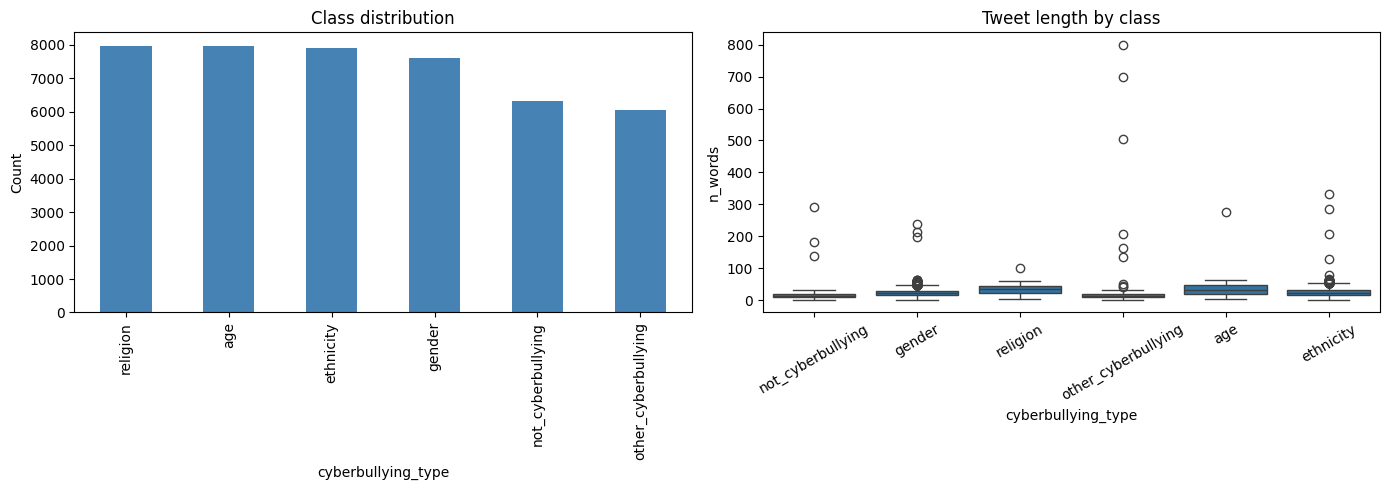

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df[LABEL_COL].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Class distribution")
axes[0].set_ylabel("Count")

df["n_words"] = df["clean"].str.split().str.len()
sns.boxplot(data=df, x=LABEL_COL, y="n_words", ax=axes[1])
axes[1].set_title("Tweet length by class")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


#Data Splitting

In [ ]:
X = df["clean"].values
y_raw = df[LABEL_COL].values

le = LabelEncoder().fit(y_raw)
CLASSES = list(le.classes_)
N_CLASSES = len(CLASSES)
y = le.transform(y_raw)

X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.1765, stratify=y_tmp, random_state=SEED)

print("Train:", len(X_train), "| Val:", len(X_val), "| Test:", len(X_test))
print("Classes:", CLASSES)


Train: 30675 | Val: 6575 | Test: 6574
Classes: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']


In [ ]:
from sklearn.metrics import precision_score, recall_score

RESULTS = []

def score_model(name, y_true, y_pred, y_score=None, family="ML", notes=""):
    row = {
        "experiment": name,
        "family": family,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "notes": notes,
    }
    if y_score is not None:
        y_bin = label_binarize(y_true, classes=np.arange(N_CLASSES))
        row["macro_auc_ovr"] = roc_auc_score(y_bin, y_score,
                                             average="macro", multi_class="ovr")
    RESULTS.append(row)
    print(f"{name}: acc={row['accuracy']:.4f}  "
          f"P={row['macro_precision']:.4f}  R={row['macro_recall']:.4f}  "
          f"macro_f1={row['macro_f1']:.4f}")
    return row

def per_class_report(name, y_true, y_pred):
    """Per-class precision, recall, and F1 for error analysis."""
    report = classification_report(y_true, y_pred, target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    return pd.DataFrame(report).T.loc[CLASSES, ["precision", "recall", "f1-score", "support"]]

def log_wandb(row, config):
    run = wandb.init(project="cyberbullying-summative", name=row["experiment"],
                     config=config, mode="offline", reinit=True)
    wandb.log({k: v for k, v in row.items() if isinstance(v, (int, float))})
    run.finish()

yva = y_val


#Experiment 1: Logistic Regression Baseline

In [ ]:
vec_word = TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                           max_features=50_000, sublinear_tf=True)
Xtr_w = vec_word.fit_transform(X_train)
Xva_w = vec_word.transform(X_val)

clf_e1 = LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)
clf_e1.fit(Xtr_w, y_train)

row_e1 = score_model("E1 LR word TF-IDF C=1", yva,
                     clf_e1.predict(Xva_w), clf_e1.predict_proba(Xva_w),
                     notes="baseline, unweighted, word 1-2gram")
log_wandb(row_e1, {"model": "logreg", "C": 1.0, "features": "word 1-2gram"})


E1 LR word TF-IDF C=1: acc=0.8643  P=0.8508  R=0.8504  macro_f1=0.8498


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86433
macro_auc_ovr,0.97773
macro_f1,0.84976
macro_precision,0.8508
macro_recall,0.85036


#Experiment 2: Logistic Regression (Regularization)

In [ ]:
best_lr, best_C, best_f1 = None, None, -1

for C in [0.1, 1.0, 10.0, 30.0]:
    clf = LogisticRegression(C=C, max_iter=2000, random_state=SEED)
    clf.fit(Xtr_w, y_train)
    row = score_model(f"E2 LR C={C}", yva, clf.predict(Xva_w),
                      clf.predict_proba(Xva_w),
                      notes="C sweep on word TF-IDF")
    log_wandb(row, {"model": "logreg", "C": C})
    if row["macro_f1"] > best_f1:
        best_lr, best_C, best_f1 = clf, C, row["macro_f1"]

print(f"Best C on validation: {best_C} (macro F1 = {best_f1:.4f})")



E2 LR C=0.1: acc=0.8379  P=0.8241  R=0.8215  macro_f1=0.8194


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.83787
macro_auc_ovr,0.96784
macro_f1,0.81941
macro_precision,0.82407
macro_recall,0.82149


E2 LR C=1.0: acc=0.8643  P=0.8508  R=0.8504  macro_f1=0.8498


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86433
macro_auc_ovr,0.97773
macro_f1,0.84976
macro_precision,0.8508
macro_recall,0.85036


E2 LR C=10.0: acc=0.8660  P=0.8520  R=0.8517  macro_f1=0.8515


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86601
macro_auc_ovr,0.97779
macro_f1,0.85153
macro_precision,0.85201
macro_recall,0.85173


E2 LR C=30.0: acc=0.8636  P=0.8489  R=0.8488  macro_f1=0.8484


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86357
macro_auc_ovr,0.97651
macro_f1,0.84844
macro_precision,0.84893
macro_recall,0.84881


Best C on validation: 10.0 (macro F1 = 0.8515)


#Experiment 3: Class-Weighted Logistic Regression

In [ ]:
clf_e3 = LogisticRegression(C=best_C, max_iter=2000,
                            class_weight="balanced", random_state=SEED)
clf_e3.fit(Xtr_w, y_train)

row_e3 = score_model(f"E3 LR C={best_C} balanced", yva,
                     clf_e3.predict(Xva_w), clf_e3.predict_proba(Xva_w),
                     notes="class_weight=balanced")
log_wandb(row_e3, {"model": "logreg", "C": best_C, "class_weight": "balanced"})


E3 LR C=10.0 balanced: acc=0.8671  P=0.8541  R=0.8533  macro_f1=0.8531


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86707
macro_auc_ovr,0.97742
macro_f1,0.85308
macro_precision,0.85408
macro_recall,0.85333


#Experiment 4: Word + Character TF-IDF (Feature Engineering)


In [ ]:
vec_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                           min_df=3, max_features=50_000, sublinear_tf=True)
Xtr_c = vec_char.fit_transform(X_train)
Xva_c = vec_char.transform(X_val)

Xtr_wc = hstack([Xtr_w, Xtr_c]).tocsr()
Xva_wc = hstack([Xva_w, Xva_c]).tocsr()

clf_e4 = LogisticRegression(C=best_C, max_iter=2000,
                            class_weight="balanced", random_state=SEED)
clf_e4.fit(Xtr_wc, y_train)

row_e4 = score_model(f"E4 LR word+char C={best_C}", yva,
                     clf_e4.predict(Xva_wc), clf_e4.predict_proba(Xva_wc),
                     notes="word 1-2gram + char_wb 2-5gram, balanced")
log_wandb(row_e4, {"model": "logreg", "C": best_C, "features": "word+char"})


E4 LR word+char C=10.0: acc=0.8817  P=0.8699  R=0.8697  macro_f1=0.8694


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.88167
macro_auc_ovr,0.98071
macro_f1,0.86938
macro_precision,0.86986
macro_recall,0.86971


#Experiment 5:LinearSVC

In [ ]:
for C in [0.1, 0.5, 1.0]:
    svc = LinearSVC(C=C, class_weight="balanced", random_state=SEED, max_iter=5000)
    svc.fit(Xtr_w, y_train)
    row = score_model(f"E5 LinearSVC C={C}", yva,
                      svc.predict(Xva_w), svc.decision_function(Xva_w),
                      notes="balanced, word TF-IDF")
    log_wandb(row, {"model": "linearsvc", "C": C})


E5 LinearSVC C=0.1: acc=0.8639  P=0.8519  R=0.8501  macro_f1=0.8483


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86388
macro_auc_ovr,0.97447
macro_f1,0.84834
macro_precision,0.85191
macro_recall,0.8501


E5 LinearSVC C=0.5: acc=0.8684  P=0.8547  R=0.8545  macro_f1=0.8534


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86844
macro_auc_ovr,0.97439
macro_f1,0.85342
macro_precision,0.85466
macro_recall,0.85447


E5 LinearSVC C=1.0: acc=0.8659  P=0.8513  R=0.8514  macro_f1=0.8504


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86586
macro_auc_ovr,0.97277
macro_f1,0.85043
macro_precision,0.85134
macro_recall,0.85138


#Experiment 6: Complement Naive Bayes

In [ ]:
for alpha in [0.1, 0.5, 1.0]:
    nb = ComplementNB(alpha=alpha)
    nb.fit(Xtr_w, y_train)
    row = score_model(f"E6 ComplementNB alpha={alpha}", yva,
                      nb.predict(Xva_w), nb.predict_proba(Xva_w),
                      notes="word TF-IDF")
    log_wandb(row, {"model": "complement_nb", "alpha": alpha})


E6 ComplementNB alpha=0.1: acc=0.8018  P=0.7864  R=0.7767  macro_f1=0.7694


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.80183
macro_auc_ovr,0.96811
macro_f1,0.76937
macro_precision,0.7864
macro_recall,0.77673


E6 ComplementNB alpha=0.5: acc=0.8055  P=0.7911  R=0.7809  macro_f1=0.7743


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.80548
macro_auc_ovr,0.9689
macro_f1,0.77431
macro_precision,0.79105
macro_recall,0.78094


E6 ComplementNB alpha=1.0: acc=0.8052  P=0.7913  R=0.7802  macro_f1=0.7732


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.80517
macro_auc_ovr,0.96913
macro_f1,0.77317
macro_precision,0.79135
macro_recall,0.78016


#Experiment 7: Random Forest

In [ ]:
rf = RandomForestClassifier(n_estimators=200, max_depth=None,
                            class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED)
rf.fit(Xtr_w, y_train)

row_e7 = score_model("E7 RandomForest 200 trees", yva,
                     rf.predict(Xva_w), rf.predict_proba(Xva_w),
                     notes="balanced_subsample, word TF-IDF")
log_wandb(row_e7, {"model": "random_forest", "n_estimators": 200})


E7 RandomForest 200 trees: acc=0.8576  P=0.8506  R=0.8444  macro_f1=0.8432


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.85764
macro_auc_ovr,0.97472
macro_f1,0.84319
macro_precision,0.85058
macro_recall,0.84441


#Deep Learning Setup with tf.data and Text Vectorization

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

MAX_TOKENS = 30_000
SEQ_LEN = 60
BATCH = 128

def make_ds(texts, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (texts.astype(str), labels.astype("int32")))
    if shuffle:
        ds = ds.shuffle(10_000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).cache().prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds = make_ds(X_val, y_val)

text_vec = layers.TextVectorization(max_tokens=MAX_TOKENS,
                                    output_mode="int",
                                    output_sequence_length=SEQ_LEN)
text_vec.adapt(tf.data.Dataset.from_tensor_slices(X_train).batch(512))

def build_text_model(kind="bilstm", emb_dim=128, units=64,
                     dropout=0.3, lr=1e-3, filters=128):
    inp = keras.Input(shape=(1,), dtype=tf.string)
    x = text_vec(inp)
    x = layers.Embedding(MAX_TOKENS, emb_dim,
                         mask_zero=(kind == "bilstm"))(x)
    if kind == "bilstm":
        # use_cudnn=False avoids the right-padding mask assertion
        x = layers.Bidirectional(layers.LSTM(units, use_cudnn=False))(x)
    elif kind == "cnn":
        x = layers.Conv1D(filters, 5, activation="relu")(x)
        x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    model = keras.Model(inp, out, name=kind)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def get_callbacks(path):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=1),
        keras.callbacks.ModelCheckpoint(path, monitor="val_loss",
                                        save_best_only=True),
    ]

def run_dl(name, model, epochs=10, config=None, ckpt=None, class_weight=None):
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     callbacks=get_callbacks(ckpt), class_weight=class_weight,
                     verbose=2)
    proba = model.predict(val_ds, verbose=0)
    row = score_model(name, yva, proba.argmax(1), proba,
                      family="DL", notes=str(config))
    log_wandb(row, config or {})
    return hist


#Experiment 8: Bidirectional LSTM Baseline
Bidirectional LSTMs reads each tweet forward and backward, so they can use context on both sides of a harmful phrase. This experiment uses 128-dimensional embeddings, 64 LSTM units, and dropout of 0.3.

In [ ]:
bilstm_base = build_text_model("bilstm", emb_dim=128, units=64,
                               dropout=0.3, lr=1e-3)
hist_e8 = run_dl("E8 BiLSTM baseline", bilstm_base, epochs=10,
                 config={"kind": "bilstm", "emb": 128, "units": 64,
                         "dropout": 0.3, "lr": 1e-3},
                 ckpt="models/e8_bilstm.keras")


Epoch 1/10
240/240 - 66s - 274ms/step - accuracy: 0.7305 - loss: 0.6914 - val_accuracy: 0.8476 - val_loss: 0.3997 - learning_rate: 0.0010
Epoch 2/10
240/240 - 58s - 242ms/step - accuracy: 0.8898 - loss: 0.3043 - val_accuracy: 0.8631 - val_loss: 0.3647 - learning_rate: 0.0010
Epoch 3/10
240/240 - 58s - 241ms/step - accuracy: 0.9362 - loss: 0.1861 - val_accuracy: 0.8578 - val_loss: 0.4146 - learning_rate: 0.0010
Epoch 4/10
240/240 - 57s - 236ms/step - accuracy: 0.9656 - loss: 0.1071 - val_accuracy: 0.8552 - val_loss: 0.4612 - learning_rate: 5.0000e-04
Epoch 5/10
240/240 - 56s - 233ms/step - accuracy: 0.9763 - loss: 0.0783 - val_accuracy: 0.8587 - val_loss: 0.4903 - learning_rate: 2.5000e-04
E8 BiLSTM baseline: acc=0.8631  P=0.8509  R=0.8499  macro_f1=0.8499


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86312
macro_auc_ovr,0.97771
macro_f1,0.84995
macro_precision,0.85087
macro_recall,0.84994


#Experiment 9: 1D CNN
This experiment tests whether local patterns are enough for compared with the sequence aware BiLSTM.

In [ ]:
cnn = build_text_model("cnn", emb_dim=128, dropout=0.3, lr=1e-3, filters=128)
hist_e9 = run_dl("E9 1D CNN", cnn, epochs=10,
                 config={"kind": "cnn", "emb": 128, "filters": 128,
                         "kernel": 5, "dropout": 0.3, "lr": 1e-3},
                 ckpt="models/e9_cnn.keras")


Epoch 1/10
240/240 - 5s - 21ms/step - accuracy: 0.7470 - loss: 0.7146 - val_accuracy: 0.8523 - val_loss: 0.3868 - learning_rate: 0.0010
Epoch 2/10
240/240 - 4s - 18ms/step - accuracy: 0.8852 - loss: 0.3173 - val_accuracy: 0.8713 - val_loss: 0.3417 - learning_rate: 0.0010
Epoch 3/10
240/240 - 2s - 9ms/step - accuracy: 0.9323 - loss: 0.2032 - val_accuracy: 0.8690 - val_loss: 0.3597 - learning_rate: 0.0010
Epoch 4/10
240/240 - 3s - 11ms/step - accuracy: 0.9611 - loss: 0.1208 - val_accuracy: 0.8704 - val_loss: 0.3752 - learning_rate: 5.0000e-04
Epoch 5/10
240/240 - 2s - 9ms/step - accuracy: 0.9739 - loss: 0.0905 - val_accuracy: 0.8677 - val_loss: 0.3903 - learning_rate: 2.5000e-04
E9 1D CNN: acc=0.8713  P=0.8587  R=0.8574  macro_f1=0.8577


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.87133
macro_auc_ovr,0.97996
macro_f1,0.85772
macro_precision,0.85867
macro_recall,0.8574


#Experiment10: Regularized BiLSTM
In this cell, I increased the dropout to (0.5) to reduce variance,lowered learning rate (5e-4) for stable optimization, and balanced class weights.

In [ ]:
y_train_int = np.asarray(y_train)
cw_values = compute_class_weight("balanced", classes=np.arange(N_CLASSES),
                                 y=y_train_int)
cw = {i: w for i, w in enumerate(cw_values)}

bilstm_reg = build_text_model("bilstm", emb_dim=128, units=64,
                              dropout=0.5, lr=5e-4)
hist_e10 = run_dl("E10 BiLSTM regularized + class weights", bilstm_reg,
                  epochs=12,
                  config={"kind": "bilstm", "dropout": 0.5, "lr": 5e-4,
                          "class_weight": "balanced"},
                  ckpt="models/e10_bilstm_reg.keras",
                  class_weight=cw)


Epoch 1/12
240/240 - 63s - 262ms/step - accuracy: 0.6958 - loss: 0.9142 - val_accuracy: 0.8307 - val_loss: 0.4655 - learning_rate: 5.0000e-04
Epoch 2/12
240/240 - 56s - 234ms/step - accuracy: 0.8610 - loss: 0.4162 - val_accuracy: 0.8546 - val_loss: 0.3998 - learning_rate: 5.0000e-04
Epoch 3/12
240/240 - 85s - 354ms/step - accuracy: 0.9110 - loss: 0.2861 - val_accuracy: 0.8622 - val_loss: 0.3913 - learning_rate: 5.0000e-04
Epoch 4/12
240/240 - 58s - 241ms/step - accuracy: 0.9390 - loss: 0.2043 - val_accuracy: 0.8570 - val_loss: 0.4111 - learning_rate: 5.0000e-04
Epoch 5/12
240/240 - 58s - 240ms/step - accuracy: 0.9591 - loss: 0.1420 - val_accuracy: 0.8624 - val_loss: 0.4346 - learning_rate: 2.5000e-04
Epoch 6/12
240/240 - 81s - 337ms/step - accuracy: 0.9672 - loss: 0.1147 - val_accuracy: 0.8610 - val_loss: 0.4543 - learning_rate: 1.2500e-04
E10 BiLSTM regularized + class weights: acc=0.8622  P=0.8531  R=0.8494  macro_f1=0.8505


accuracy,▁
macro_auc_ovr,▁
macro_f1,▁
macro_precision,▁
macro_recall,▁
weighted_f1,▁
accuracy,0.86221
macro_auc_ovr,0.97573
macro_f1,0.85049
macro_precision,0.85313
macro_recall,0.84938


#Final Test Evaluation, Learning Curves, Confusion Matrices, and ROC
This cell uses the test sset to select the best model from the validation results.Learning curves show training dynamics, the confusion matrix shows how different classes are confused,and ROC curves compare one-vs-rest separability per class.

Selection rule: macro F1 on validation.

Best ML (validation): E4 LR word+char C=10.0
Best DL (validation): E9 1D CNN

TEST — Best ML
                     precision    recall  f1-score   support

                age      0.974     0.976     0.975      1194
          ethnicity      0.985     0.987     0.986      1188
             gender      0.920     0.862     0.890      1142
  not_cyberbullying      0.679     0.675     0.677       947
other_cyberbullying      0.698     0.770     0.732       906
           religion      0.958     0.943     0.951      1197

           accuracy                          0.880      6574
          macro avg      0.869     0.869     0.868      6574
       weighted avg      0.883     0.880     0.881      6574


TEST — Best DL
                     precision    recall  f1-score   support

                age      0.976     0.959     0.967      1194
          ethnicity      0.963     0.988     0.975      1188
             gender      0.898     0.859     0.878      1142
  not_cyberbullying      0.649   

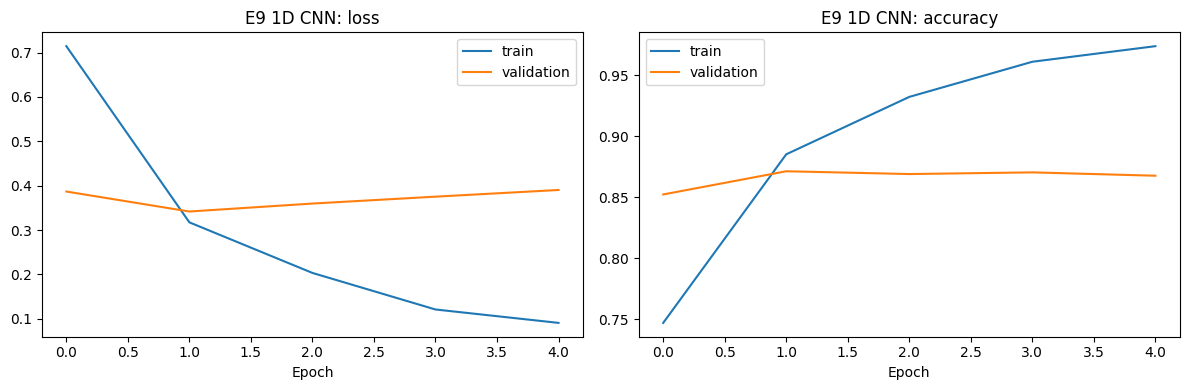

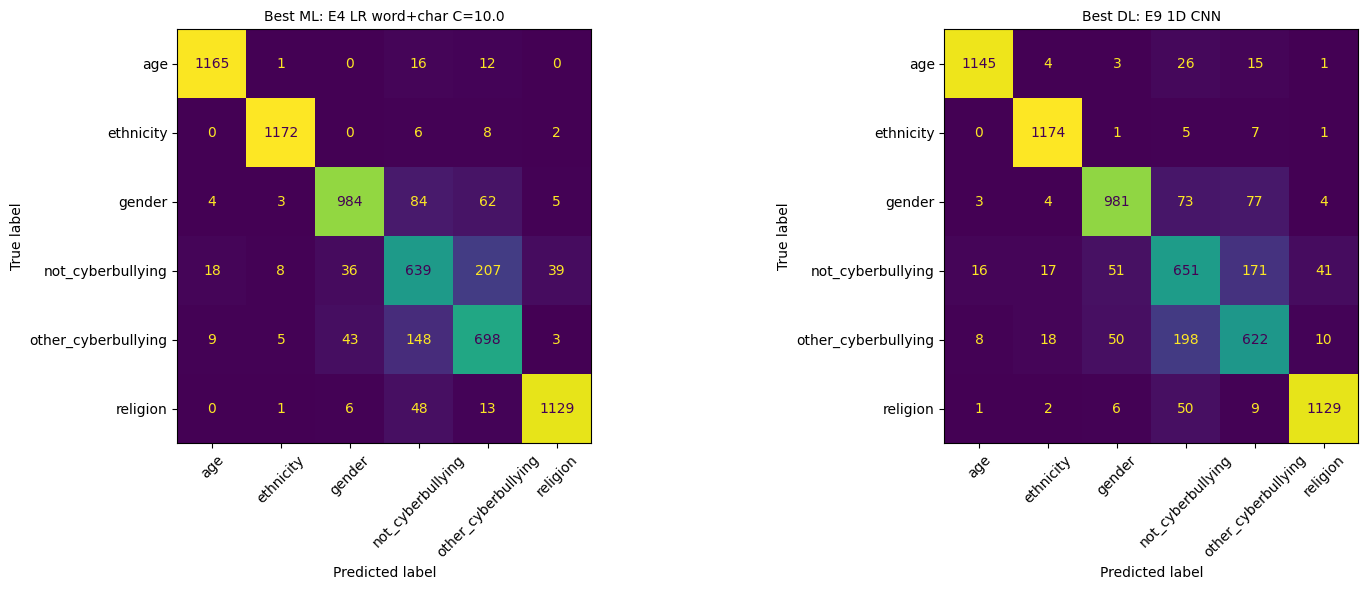

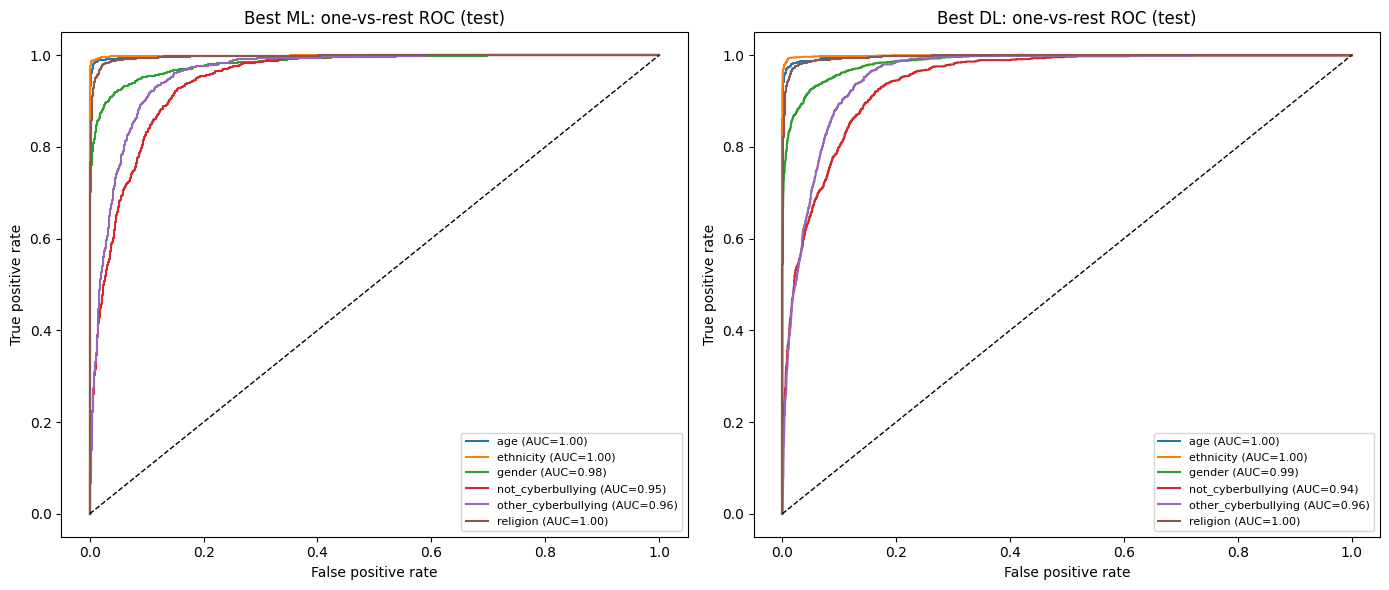

In [ ]:
from sklearn.metrics import (roc_curve, auc, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

# best model on validation
results_df = pd.DataFrame(RESULTS)
best_ml_name = (results_df[results_df.family == "ML"]
                .sort_values("macro_f1", ascending=False).iloc[0]["experiment"])
best_dl_name = (results_df[results_df.family == "DL"]
                .sort_values("macro_f1", ascending=False).iloc[0]["experiment"])
print("Best ML (validation):", best_ml_name)
print("Best DL (validation):", best_dl_name)

ML_REGISTRY = {
    "E1 LR word TF-IDF C=1":      (clf_e1, "word"),
    f"E2 LR C={best_C}":          (best_lr, "word"),
    f"E3 LR C={best_C} balanced": (clf_e3, "word"),
    f"E4 LR word+char C={best_C}": (clf_e4, "wordchar"),
    "E7 RandomForest 200 trees":  (rf, "word"),
}
if best_ml_name not in ML_REGISTRY:
    raise ValueError(f"'{best_ml_name}' is not stored in ML_REGISTRY. "
                     "Store its fitted model in its experiment cell first.")

def ml_test_features(kind):
    Xw = vec_word.transform(X_test)
    if kind == "word":
        return Xw
    return hstack([Xw, vec_char.transform(X_test)]).tocsr()

best_ml, ml_feat = ML_REGISTRY[best_ml_name]
ml_proba = best_ml.predict_proba(ml_test_features(ml_feat))
ml_pred = ml_proba.argmax(1)

DL_REGISTRY = {
    "E8":  ("models/e8_bilstm.keras",      hist_e8),
    "E9":  ("models/e9_cnn.keras",         hist_e9),
    "E10": ("models/e10_bilstm_reg.keras", hist_e10),
}
dl_key = best_dl_name.split()[0]
ckpt_path, best_hist = DL_REGISTRY[dl_key]

best_dl = keras.models.load_model(ckpt_path)
dl_proba = best_dl.predict(make_ds(X_test, y_test), verbose=0)
dl_pred = dl_proba.argmax(1)

# Test metrics
TEST_RESULTS = []
y_bin_test = label_binarize(y_test, classes=np.arange(N_CLASSES))

def score_test(name, family, proba):
    y_pred = proba.argmax(1)
    row = {
        "model": name,
        "family": family,
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_auc_ovr": roc_auc_score(y_bin_test, proba, average="macro", multi_class="ovr"),
    }
    TEST_RESULTS.append(row)
    return row

row_ml_test = score_test(best_ml_name, "ML", ml_proba)
row_dl_test = score_test(best_dl_name, "DL", dl_proba)

print("\nTEST — Best ML")
print(classification_report(y_test, ml_pred, target_names=CLASSES, digits=3, zero_division=0))
print("\nTEST — Best DL")
print(classification_report(y_test, dl_pred, target_names=CLASSES, digits=3, zero_division=0))

test_df = pd.DataFrame(TEST_RESULTS)
test_df.to_csv("results/test_results.csv", index=False)
print("\nTest summary (saved to results/test_results.csv):")
print(test_df.to_string(index=False))

#Learning curves
def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.history["loss"], label="train")
    ax[0].plot(hist.history["val_loss"], label="validation")
    ax[0].set_title(f"{title}: loss")
    ax[0].set_xlabel("Epoch")
    ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train")
    ax[1].plot(hist.history["val_accuracy"], label="validation")
    ax[1].set_title(f"{title}: accuracy")
    ax[1].set_xlabel("Epoch")
    ax[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(best_hist, best_dl_name)

#  Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, pred, title in [(axes[0], ml_pred, f"Best ML: {best_ml_name}"),
                        (axes[1], dl_pred, f"Best DL: {best_dl_name}")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=CLASSES, ax=ax,
        xticks_rotation=45, colorbar=False)
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

#  ROC curves
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, proba, title in [(axes[0], ml_proba, "Best ML"),
                         (axes[1], dl_proba, "Best DL")]:
    for i, cls in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(y_bin_test[:, i], proba[:, i])
        ax.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"{title}: one-vs-rest ROC (test)")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()


#Save Models and Results Table

This cell shows the results table and saves the best modelas a joblib.

In [ ]:
results_df = pd.DataFrame(RESULTS)
results_df.to_csv("results/experiment_table.csv", index=False)
print(results_df.sort_values("macro_f1", ascending=False).to_string(index=False))

from sklearn.pipeline import Pipeline
best_ml_pipeline = Pipeline([("tfidf", vec_word), ("clf", best_ml)])
joblib.dump(best_ml_pipeline, "models/best_ml_pipeline.joblib")

best_dl.export("models/saved_model_best_dl")
print("Saved: models/best_ml_pipeline.joblib and models/saved_model_best_dl/")


                            experiment family  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1                                                                                 notes  macro_auc_ovr
                E4 LR word+char C=10.0     ML  0.881673         0.869862      0.869707  0.869384     0.882403                                              word 1-2gram + char_wb 2-5gram, balanced       0.980709
                             E9 1D CNN     DL  0.871331         0.858668      0.857404  0.857722     0.871856 {'kind': 'cnn', 'emb': 128, 'filters': 128, 'kernel': 5, 'dropout': 0.3, 'lr': 0.001}       0.979963
                    E5 LinearSVC C=0.5     ML  0.868441         0.854657      0.854473  0.853425     0.867969                                                                 balanced, word TF-IDF       0.974389
                 E3 LR C=10.0 balanced     ML  0.867072         0.854082      0.853326  0.853080     0.868003                                               

#